         Time  Transfer Function Response  ODE Response
0     0.00000                0.000000e+00      0.000000
1     0.01001                6.288438e-02      0.000315
2     0.02002                1.257066e-01      0.001259
3     0.03003                1.884045e-01      0.002831
4     0.04004                2.509161e-01      0.005030
..        ...                         ...           ...
995   9.95996               -2.509161e-01      0.005160
996   9.96997               -1.884045e-01      0.002961
997   9.97998               -1.257066e-01      0.001389
998   9.98999               -6.288438e-02      0.000445
999  10.00000               -2.449294e-15      0.000130

[1000 rows x 3 columns]


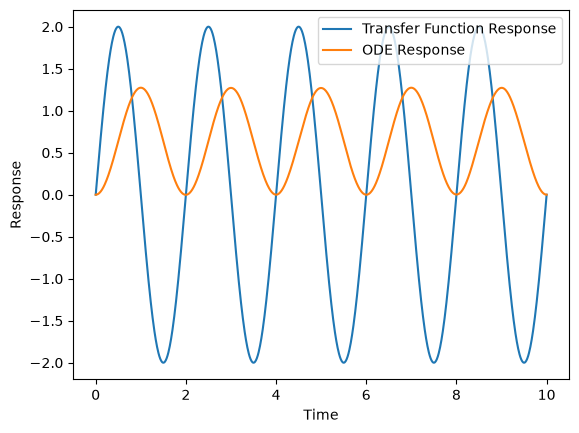

                      Metodo Funcion de Tranferencia  \
0                                  Transfer Function   
1  se utiliza la transformada de Laplace para mod...   
2                                                      

                     Metodo ecuaciones diferenciales  
0  Ideal para situaciones con condiciones inicial...  
1             No se requiere transformada de Laplace  
2                                               Good  


: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp   

#ayuda para la simulacion de sistemas por funcion de transferencia y por ecuaciones diferenciales con condiciones iniciales
def compare_simulation(transfer_function, initial_conditions, time_span):
    # Simulación por función de transferencia
    t = np.linspace(time_span[0], time_span[1], 1000)
    system_response = transfer_function(t)

    # Simulación por ecuaciones diferenciales con condiciones iniciales
    def ode_system(t, y):
        return transfer_function(t)  # Suponiendo que la función de transferencia es una función de tiempo

    sol = solve_ivp(ode_system, time_span, initial_conditions, t_eval=t)

    # Crear un DataFrame para comparar los resultados
    comparison_df = pd.DataFrame({
        'Time': t,
        'Transfer Function Response': system_response,
        'ODE Response': sol.y[0]  # Suponiendo que la respuesta es unidimensional
    })

    return comparison_df

# Ejemplo de uso
transfer_function = lambda t: 2 * np.sin(2 * np.pi * 0.5 * t)
initial_conditions = [0, 0]
time_span = (0, 10)

comparison_df = compare_simulation(transfer_function, initial_conditions, time_span)

print(comparison_df)

# Graficar los resultados
plt.plot(comparison_df['Time'], comparison_df['Transfer Function Response'], label='Transfer Function Response')
plt.plot(comparison_df['Time'], comparison_df['ODE Response'], label='ODE Response')
plt.xlabel('Time')
plt.ylabel('Response')
plt.legend()
plt.show()

#Generar tabla comparativa  de caracteristicas entre los 2 metodos de simulacion
comparison_table = pd.DataFrame({
    ' Metodo Funcion de Tranferencia': ['Transfer Function','se utiliza la transformada de Laplace para modelar sistemas lineales','dependiendo del sistema puede ser mas facil de resolver','id'],
    ' Metodo ecuaciones diferenciales': ['Ideal para situaciones con condiciones iniciales conocidas','No se requiere transformada de Laplace','dependiendo del sistema puede ser mas complejo de resolver',''],
    
})

print(comparison_table)